In [18]:

#Load & Inspect Data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_excel('ABC Company.xlsx')
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (458, 9)


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0


In [19]:
#Preprocessing


np.random.seed(42)
df['Height'] = np.random.randint(150, 181, size=len(df))

df['College'] = df['College'].fillna('No College / International')
df['Salary'] = df['Salary'].fillna(df['Salary'].median())

print("Missing values after cleaning:\n", df.isnull().sum())
print("\nHeight summary:\n", df['Height'].describe())


Missing values after cleaning:
 Name        0
Team        0
Number      0
Position    0
Age         0
Height      0
Weight      0
College     0
Salary      0
dtype: int64

Height summary:
 count    458.000000
mean     165.085153
std        9.412232
min      150.000000
25%      156.250000
50%      165.000000
75%      174.000000
max      180.000000
Name: Height, dtype: float64


,Employee Count,Percentage (%)
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
Utah Jazz,16,3.49
Milwaukee Bucks,16,3.49
New York Knicks,16,3.49
Boston Celtics,15,3.28
Los Angeles Clippers,15,3.28
Los Angeles Lakers,15,3.28
Phoenix Suns,15,3.28


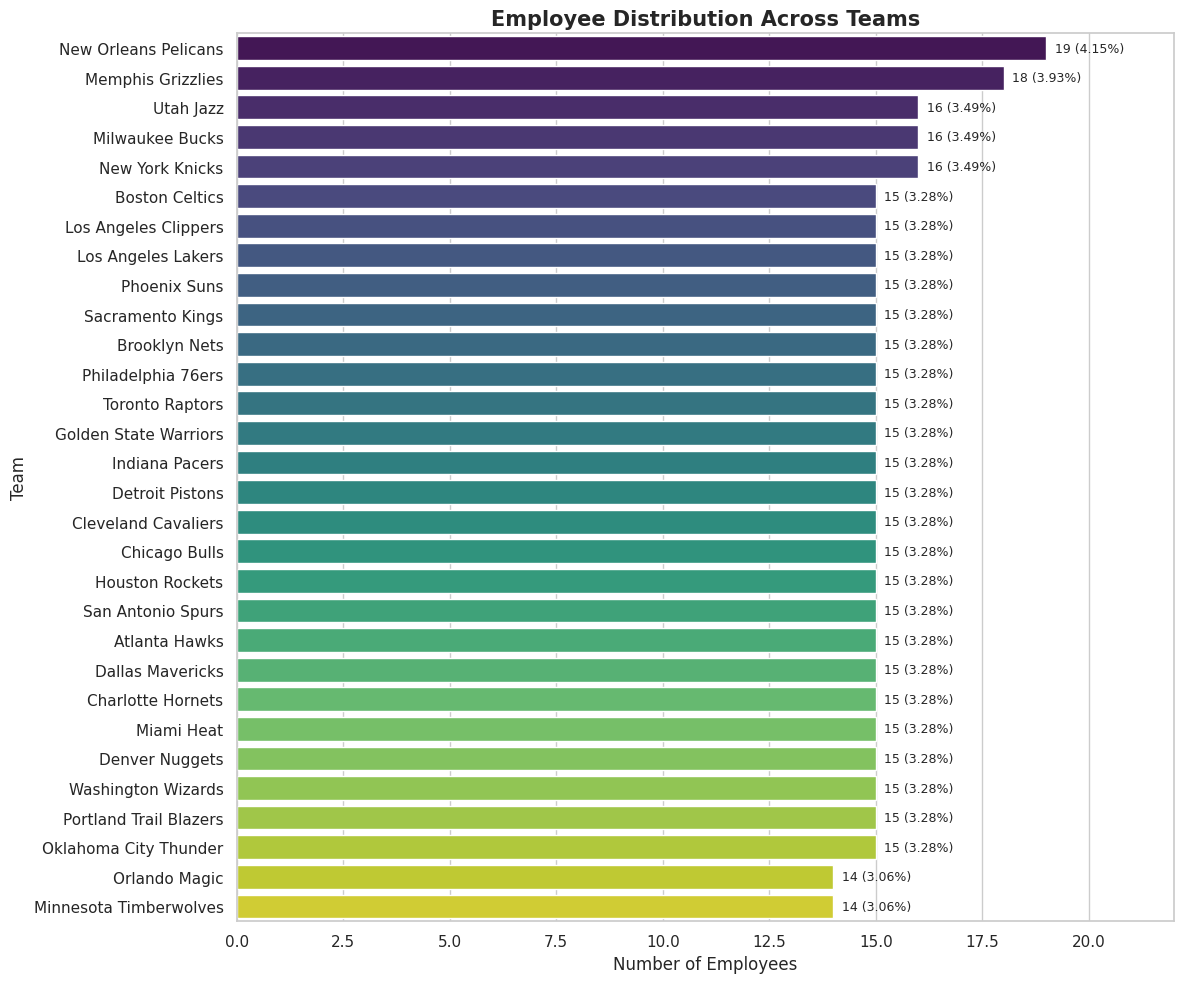

In [20]:
#Team Distribution & Percentage Split

team_counts = df['Team'].value_counts()
team_pct = (team_counts / len(df) * 100).round(2)

team_df = pd.DataFrame({'Employee Count': team_counts, 'Percentage (%)': team_pct})
display(team_df)

plt.figure(figsize=(12, 10))
ax = sns.barplot(x=team_counts.values, y=team_counts.index, palette='viridis')
plt.title('Employee Distribution Across Teams', fontsize=15, fontweight='bold')
plt.xlabel('Number of Employees')
plt.ylabel('Team')
for i, v in enumerate(team_counts.values):
    ax.text(v + 0.2, i, f"{v} ({team_pct.iloc[i]}%)", va='center', fontsize=9)
plt.xlim(0, team_counts.max() + 3)
plt.tight_layout()
plt.show()


Predominant Age Group: 23-26 (170 employees)


,Employee Count
Age_Group,
19-22,66
23-26,170
27-30,131
31-34,59
35+,32


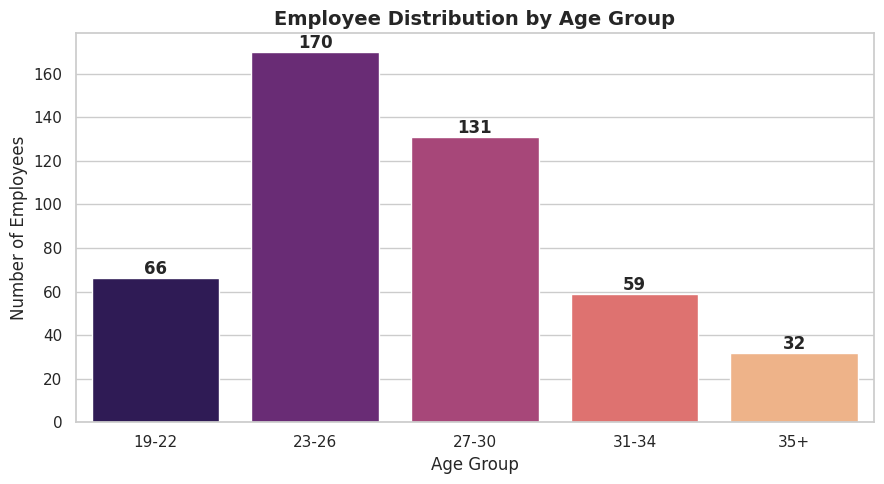

In [21]:
#Segregate by Position

bins = [18, 22, 26, 30, 34, 45]
labels = ['19-22', '23-26', '27-30', '31-34', '35+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

age_counts = df['Age_Group'].value_counts().sort_index()
predominant_age = age_counts.idxmax()
print(f"Predominant Age Group: {predominant_age} ({age_counts.max()} employees)")
display(age_counts.to_frame(name='Employee Count'))

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=age_counts.index, y=age_counts.values, palette='magma')
plt.title('Employee Distribution by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


Predominant Age Group: 23-26 (170 employees)


,Employee Count
Age_Group,
19-22,66
23-26,170
27-30,131
31-34,59
35+,32


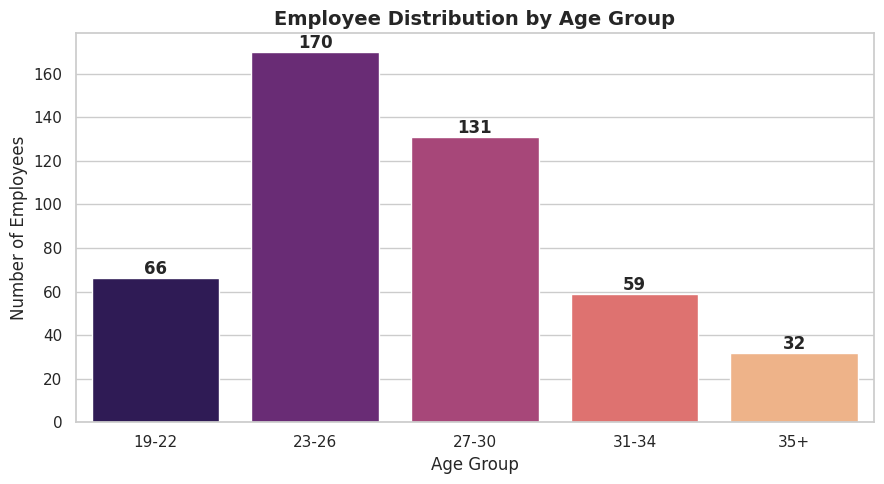

In [22]:
#Predominant Age Group

bins = [18, 22, 26, 30, 34, 45]
labels = ['19-22', '23-26', '27-30', '31-34', '35+']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

age_counts = df['Age_Group'].value_counts().sort_index()
predominant_age = age_counts.idxmax()
print(f"Predominant Age Group: {predominant_age} ({age_counts.max()} employees)")
display(age_counts.to_frame(name='Employee Count'))

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=age_counts.index, y=age_counts.values, palette='magma')
plt.title('Employee Distribution by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


Highest Salary Team: Cleveland Cavaliers ($109,824,875.00)
Highest Salary Position: C ($466,377,332.00)


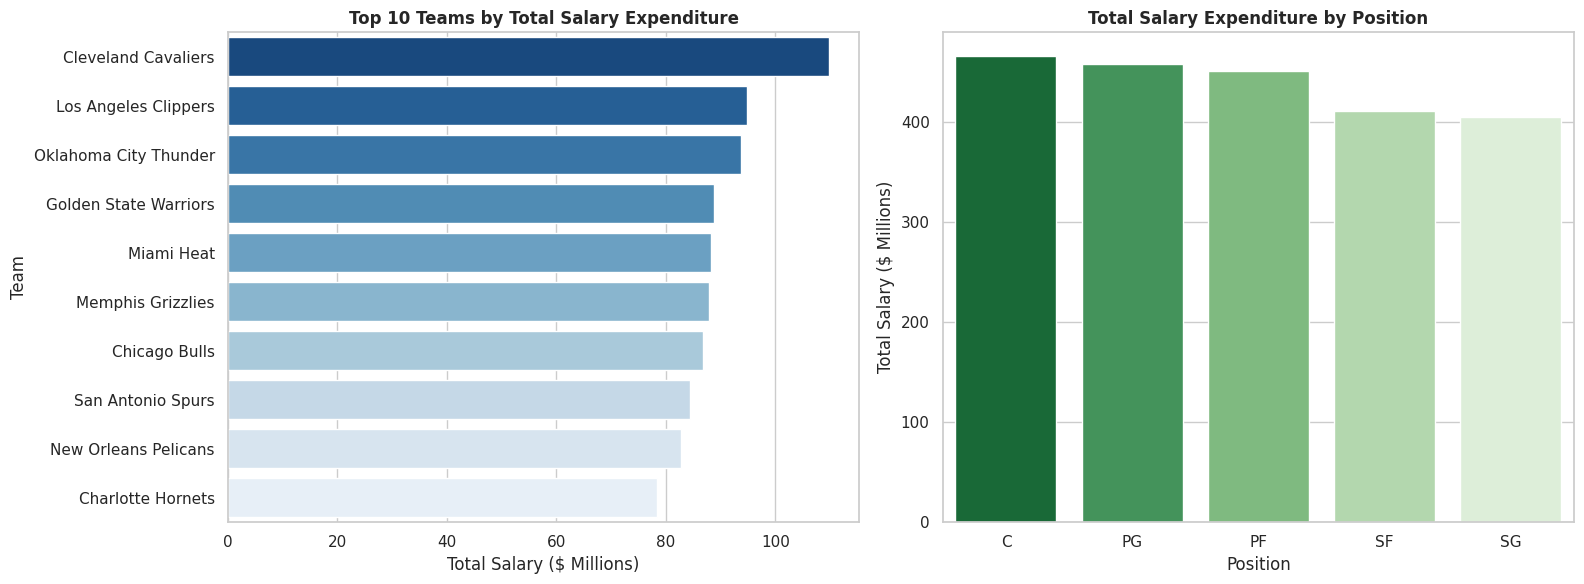

In [23]:
#Highest Salary Expenditure by Team & Position


team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
pos_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)

print(f"Highest Salary Team: {team_salary.index[0]} (${team_salary.iloc[0]:,.2f})")
print(f"Highest Salary Position: {pos_salary.index[0]} (${pos_salary.iloc[0]:,.2f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_10_teams = team_salary.head(10)
sns.barplot(x=top_10_teams.values / 1e6, y=top_10_teams.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 Teams by Total Salary Expenditure', fontweight='bold')
axes[0].set_xlabel('Total Salary ($ Millions)')

sns.barplot(x=pos_salary.index, y=pos_salary.values / 1e6, ax=axes[1], palette='Greens_r')
axes[1].set_title('Total Salary Expenditure by Position', fontweight='bold')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Total Salary ($ Millions)')
plt.tight_layout()
plt.show()


Correlation Coefficient (Age vs. Salary): 0.2091


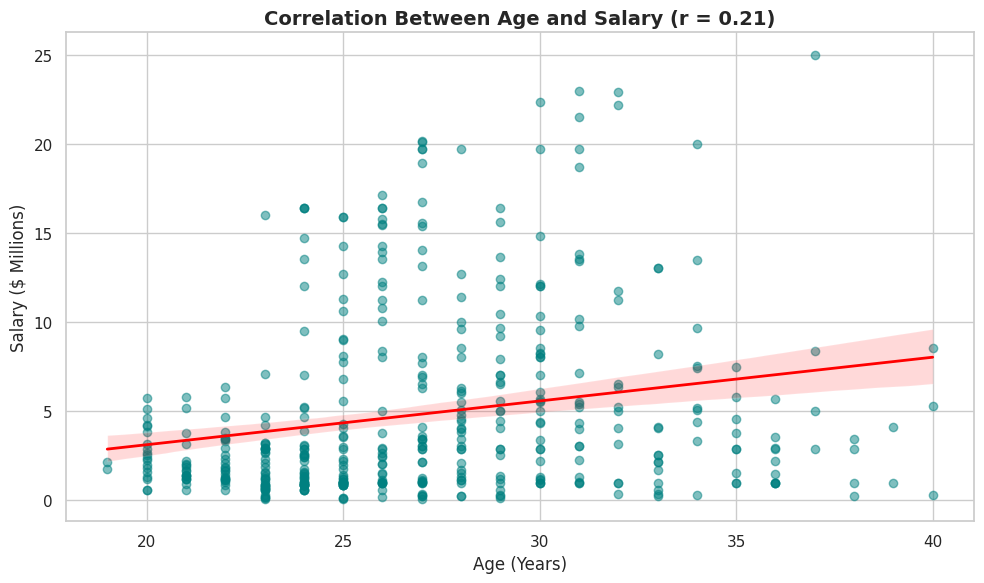

In [24]:
#Correlation Between Age and Salary

corr = df['Age'].corr(df['Salary'])
print(f"Correlation Coefficient (Age vs. Salary): {corr:.4f}")

plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='Age', y=df['Salary'] / 1e6, scatter_kws={'alpha': 0.5, 'color': 'teal'}, line_kws={'color': 'red', 'linewidth': 2})
plt.title(f'Correlation Between Age and Salary (r = {corr:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Age (Years)')
plt.ylabel('Salary ($ Millions)')
plt.tight_layout()
plt.show()


In [25]:


# Define pos_pct so Cell 8 runs independently without errors
pos_pct = (pos_counts / len(df) * 100).round(2)

readme_text = f"""# ABC Company Employee Data Analysis

## Project Overview
This project analyzes **{len(df)} employees across {df.shape[1]} attributes** at ABC Company to evaluate team structure, positional distribution, demographics, and salary expenditure.

## Preprocessing Steps
- **Height Correction:** Replaced corrupted values in `Height` with random integers between **150 and 180** (`np.random.seed(42)`).
- **Data Integrity:** Imputed missing `College` entries as `"No College / International"` and filled missing `Salary` values using the median (`${df['Salary'].median():,.2f}`).

## Key Insights (Data Story)
1. **Team Distribution:** Employees span **{df['Team'].nunique()} teams**, led by **{team_counts.index[0]}** with **{team_counts.iloc[0]} employees ({team_pct.iloc[0]}%)**.
2. **Positional Breakdown:** Segregated into **{df['Position'].nunique()} positions**, with **{pos_counts.index[0]}** forming the largest group (**{pos_counts.iloc[0]} employees, {pos_pct.iloc[0]}%**).
3. **Predominant Age Group:** The **{predominant_age}** bracket is the largest demographic (**{age_counts.max()} employees**).
4. **Salary Expenditure:** **{team_salary.index[0]}** has the highest team payroll (**${team_salary.iloc[0]:,.2f}**), and **{pos_salary.index[0]}** has the highest positional expenditure (**${pos_salary.iloc[0]:,.2f}**).
5. **Age vs. Salary Correlation:** A weak positive correlation (**`r = {corr:.2f}`**) indicates that while older employees earn slightly more on average, salary is driven primarily by role and performance rather than age alone.
"""

print(readme_text)


# ABC Company Employee Data Analysis

## Project Overview
This project analyzes **458 employees across 10 attributes** at ABC Company to evaluate team structure, positional distribution, demographics, and salary expenditure.

## Preprocessing Steps
- **Height Correction:** Replaced corrupted values in `Height` with random integers between **150 and 180** (`np.random.seed(42)`).
- **Data Integrity:** Imputed missing `College` entries as `"No College / International"` and filled missing `Salary` values using the median (`$2,836,186.00`).

## Key Insights (Data Story)
1. **Team Distribution:** Employees span **30 teams**, led by **New Orleans Pelicans** with **19 employees (4.15%)**.
2. **Positional Breakdown:** Segregated into **5 positions**, with **SG** forming the largest group (**117 employees, 25.55%**).
3. **Predominant Age Group:** The **23-26** bracket is the largest demographic (**170 employees**).
4. **Salary Expenditure:** **Cleveland Cavaliers** has the highest team payroll (